In [4]:
# import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

import tensorflow as tf
import tensorflow.keras as keras
import tensorflow_hub as hub
from tensorflow.keras import layers
from tensorflow.keras.layers import TextVectorization

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


### Loading Data, Performing EDA and preprocessing

In [5]:
# read dataset
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/projects/SMS spam detection/spam.csv')
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [6]:
# observe the 3 unnamed columns
df[['Unnamed: 2', 'Unnamed: 3','Unnamed: 4']].nunique()

,0
Unnamed: 2,0
Unnamed: 3,0
Unnamed: 4,0


In [7]:
# distribution of target classes
df.value_counts('v1')

,count
v1,
ham,4825
spam,747


In [8]:
# drop unnecessary columns and rename label and text msg
df = df.drop(['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], axis=1)
df = df.rename(columns={'v1': 'label', 'v2': 'message'})

# encode label
df['label_enc'] = df['label'].map({'ham': 0, 'spam': 1})
df.head()

,label,message,label_enc
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


### Splitting into training and testing sets

In [9]:
X = df['message']
y = df['label_enc']

X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=49, test_size=0.2)

X_train_np = X_train.to_numpy()
y_train_np = y_train.to_numpy()
X_test_np = X_test.to_numpy()
y_test_np = y_test.to_numpy()

### Text Statistics for Vectorization (avg words and vocab size)

In [10]:
word_counts = [len(i.split()) for i in df['message']]
avg_word_count = round(sum(word_counts) / len(df['message']))
tot_uniq_word_count = len(set(" ".join(df['message']).split()))

print('Training samples: {}'.format(len(X_train_np)))
print('Average words per message: {}'.format(avg_word_count))
print('Approximate vocabulary size: {}'.format(tot_uniq_word_count))

Training samples: 4457
Average words per message: 16
Approximate vocabulary size: 15686


### Model Training and Evalutation helper functions

In [11]:
# compiling and fitting
def compile_and_fit(model, epochs=5):
  model.compile(
      optimizer='adam',
      loss='binary_crossentropy',
      metrics=['accuracy']
  )
  history = model.fit(
      X_train_np,
      y_train_np,
      epochs=epochs,
      validation_data=(X_test_np, y_test_np)
  )
  return history

# evaluation
def get_metrics(model, X,y):
  y_probs = model.predict(X).ravel()
  y_preds = (y_probs >= 0.5).astype(int)
  # y_preds = np.round(model.predict)

  return {
      'accuracy': accuracy_score(y, y_preds),
      'precision': precision_score(y, y_preds),
      'recall': recall_score(y, y_preds),
      'f1-score': f1_score(y, y_preds)
  }

### Text Vectorization layer

In [12]:
text_vec = TextVectorization(
    max_tokens=tot_uniq_word_count,
    standardize='lower_and_strip_punctuation',
    output_mode='int',
    output_sequence_length=avg_word_count
)
text_vec.adapt(X_train_np)

### Training the models

**1. 1D CNN**

In [13]:
input_layer = layers.Input(shape=(1,), dtype=tf.string)

x = text_vec(input_layer)
x = layers.Embedding(input_dim=tot_uniq_word_count,output_dim=128)(x)
x = layers.Conv1D(filters=128,kernel_size=5,activation='relu')(x)
x = layers.GlobalMaxPooling1D()(x)
x = layers.Dropout(0.1)(x)
x = layers.Dense(32, activation='relu')(x)

output_layer = layers.Dense(1,activation='sigmoid')(x)

model_1_cnn = keras.Model(input_layer, output_layer, name="CNN_Model")

model_1_cnn.summary()
history_1_cnn = compile_and_fit(model_1_cnn)

Model: "CNN_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 1)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ text_vectorization              │ (None, 16)             │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 16, 128)        │     2,007,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 12, 128)        │        82,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 128)            │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,094,017 (7.99 MB)

 Trainable params: 2,094,017 (7.99 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 9s 52ms/step - accuracy: 0.9179 - loss: 0.2121 - val_accuracy: 0.9785 - val_loss: 0.0602
Epoch 2/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - accuracy: 0.9861 - loss: 0.0446 - val_accuracy: 0.9857 - val_loss: 0.0452
Epoch 3/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - accuracy: 0.9969 - loss: 0.0133 - val_accuracy: 0.9883 - val_loss: 0.0454
Epoch 4/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 6s 45ms/step - accuracy: 0.9978 - loss: 0.0079 - val_accuracy: 0.9865 - val_loss: 0.0530
Epoch 5/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 8s 32ms/step - accuracy: 0.9982 - loss: 0.0037 - val_accuracy: 0.9839 - val_loss: 0.0614


**2. Dense Embedding model**

In [14]:
input_layer = layers.Input(shape=(1,), dtype=tf.string)

x = text_vec(input_layer)
x = layers.Embedding(input_dim=tot_uniq_word_count, output_dim=128)(x)
x = layers.GlobalAveragePooling1D()(x)
x = layers.Dense(32, activation='relu')(x)

output_layer = layers.Dense(1, activation='sigmoid')(x)

model_2_dem = keras.Model(input_layer, output_layer, name="Dense_Model")

model_2_dem.summary()
history_2_dem = compile_and_fit(model_2_dem)

Model: "Dense_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 1)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ text_vectorization              │ (None, 16)             │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_1 (Embedding)         │ (None, 16, 128)        │     2,007,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,011,969 (7.68 MB)

 Trainable params: 2,011,969 (7.68 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 7s 33ms/step - accuracy: 0.8993 - loss: 0.2844 - val_accuracy: 0.9713 - val_loss: 0.1329
Epoch 2/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 7s 52ms/step - accuracy: 0.9764 - loss: 0.0912 - val_accuracy: 0.9857 - val_loss: 0.0567
Epoch 3/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 10s 72ms/step - accuracy: 0.9874 - loss: 0.0430 - val_accuracy: 0.9857 - val_loss: 0.0412
Epoch 4/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 7s 49ms/step - accuracy: 0.9935 - loss: 0.0263 - val_accuracy: 0.9865 - val_loss: 0.0386
Epoch 5/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 9s 39ms/step - accuracy: 0.9957 - loss: 0.0170 - val_accuracy: 0.9848 - val_loss: 0.0396


**3. Bidirectional LSTM model**

In [15]:
input_layer = layers.Input(shape=(1,), dtype=tf.string)

x = text_vec(input_layer)
x = layers.Embedding(input_dim=tot_uniq_word_count, output_dim=128)(x)
x = layers.Bidirectional(layers.LSTM(64, return_sequences=True))(x)
x = layers.Bidirectional(layers.LSTM(64))(x)
x = layers.Flatten()(x)
x = layers.Dropout(0.1)(x)
x = layers.Dense(32, activation='relu')(x)

output_layer = layers.Dense(1, activation='sigmoid')(x)

model_3_blstm = keras.Model(input_layer, output_layer, name="BiLSTM_Model")

model_3_blstm.summary()
history_3_blstm = compile_and_fit(model_3_blstm)

Model: "BiLSTM_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 1)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ text_vectorization              │ (None, 16)             │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_2 (Embedding)         │ (None, 16, 128)        │     2,007,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 16, 128)        │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,209,601 (8.43 MB)

 Trainable params: 2,209,601 (8.43 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 48s 183ms/step - accuracy: 0.9437 - loss: 0.1754 - val_accuracy: 0.9812 - val_loss: 0.0630
Epoch 2/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 103ms/step - accuracy: 0.9906 - loss: 0.0390 - val_accuracy: 0.9848 - val_loss: 0.0520
Epoch 3/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 98ms/step - accuracy: 0.9957 - loss: 0.0144 - val_accuracy: 0.9794 - val_loss: 0.0727
Epoch 4/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 20s 92ms/step - accuracy: 0.9991 - loss: 0.0035 - val_accuracy: 0.9794 - val_loss: 0.0683
Epoch 5/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 102ms/step - accuracy: 1.0000 - loss: 4.3608e-04 - val_accuracy: 0.9857 - val_loss: 0.0853


**4. Transfer learned model using Universal Sentence Encoder**

In [16]:
use_layer = hub.KerasLayer(
    "https://tfhub.dev/google/universal-sentence-encoder/4",
    trainable=False,
    input_shape=[],
    dtype=tf.string,
    name='USE'
)

input_layer = layers.Input(shape=[], dtype=tf.string)

embedding = layers.Lambda(lambda x: use_layer(
    x), output_shape=(512,))(input_layer)

x = layers.Dense(64, activation='relu')(embedding)
x = layers.Dropout(0.2)(x)

output_layer = layers.Dense(1, activation='sigmoid')(x)

model_4_transfl = keras.Model(input_layer, output_layer, name="USE_Model")
model_4_transfl.summary()
history_4_transfl = compile_and_fit(model_4_transfl)

Model: "USE_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None)                 │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,897 (128.50 KB)

 Trainable params: 32,897 (128.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 12s 23ms/step - accuracy: 0.9138 - loss: 0.3109 - val_accuracy: 0.9803 - val_loss: 0.1076
Epoch 2/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.9760 - loss: 0.0891 - val_accuracy: 0.9883 - val_loss: 0.0549
Epoch 3/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9834 - loss: 0.0606 - val_accuracy: 0.9901 - val_loss: 0.0430
Epoch 4/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.9845 - loss: 0.0491 - val_accuracy: 0.9919 - val_loss: 0.0381
Epoch 5/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.9859 - loss: 0.0438 - val_accuracy: 0.9919 - val_loss: 0.0359


### Visualizing training and validation metrics

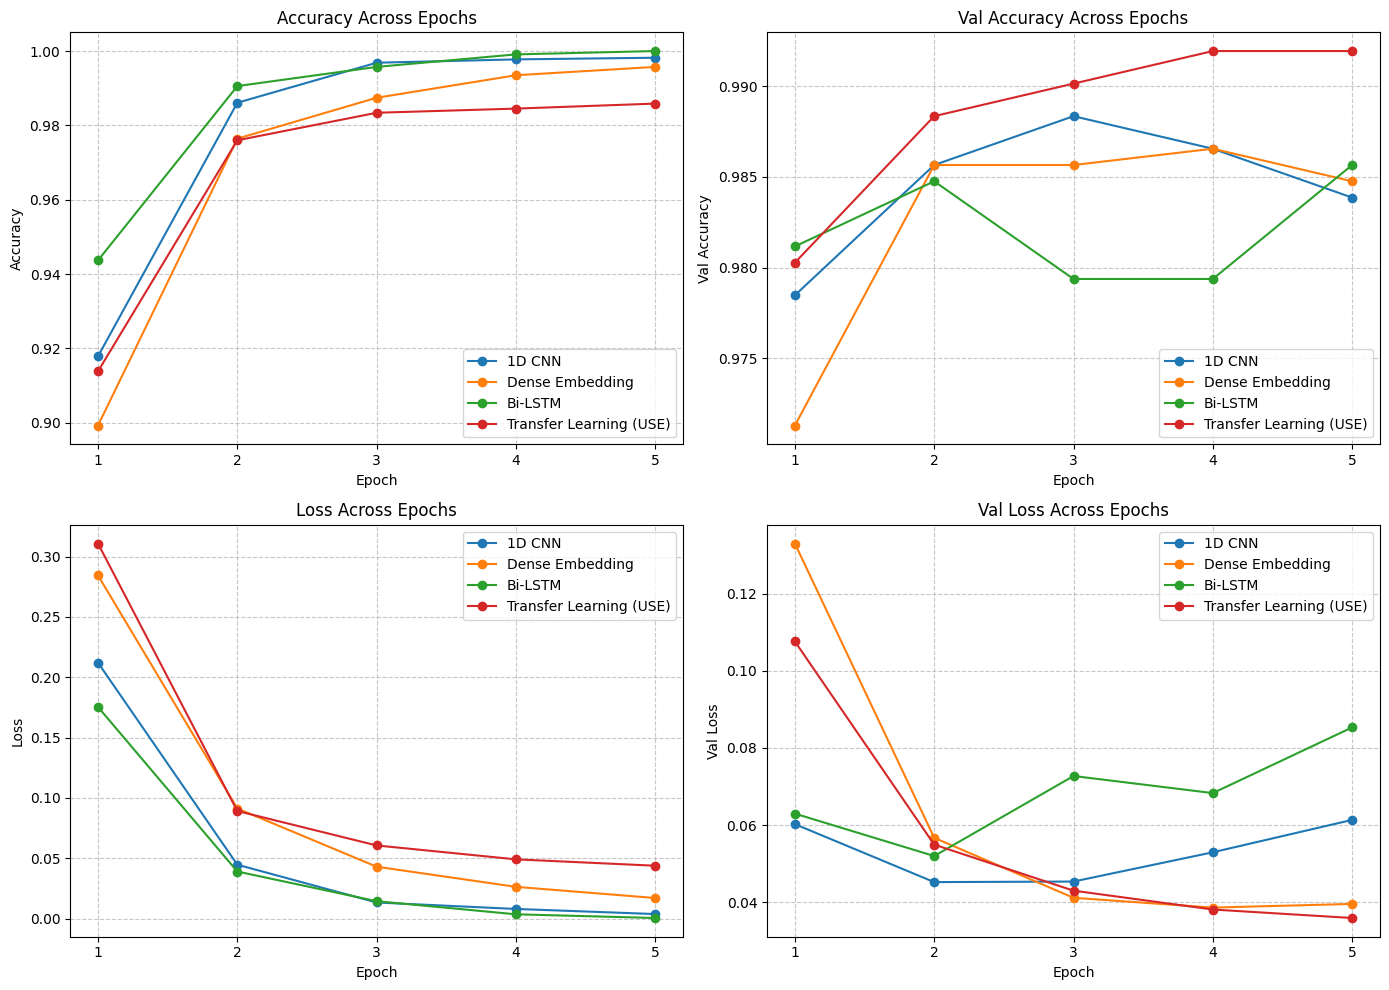

In [40]:
# save all histories as a dictionary
histories = {
    '1D CNN': history_1_cnn,
    'Dense Embedding': history_2_dem,
    'Bi-LSTM': history_3_blstm,
    'Transfer Learning (USE)': history_4_transfl
}

metrics = ['accuracy', 'val_accuracy', 'loss', 'val_loss']

# plot metrics across epochs
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14,10))
axes = axes.flatten()

for ax, metric in zip(axes, metrics):
  for model_name, history in histories.items():
    ax.plot(
        history.history[metric],
        marker='o',
        label=model_name
      )
  ax.set_title(f'{metric.replace('_', ' ').title()} Across Epochs')
  ax.set_xlabel('Epoch')
  ax.set_ylabel(metric.replace('_', ' ').title())
  ax.set_xticks(range(5))
  ax.set_xticklabels(range(1,6))
  ax.legend()
  ax.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

#### Observations:

* **Training accuracy:**
  - The accuracy of all 4 models have consistently increased over the 5 epochs. By the last epoch, all models achieve very high training accuracy (ranging from around 98.5 to 100%).

---

* **Validation accuracy:**
  - Validation accuracy is generally high for all models. However, it doesn't consistently increase for all models across epochs. The 1D CNN reaches its highest accuracy on the third epoch and gradually decreased afterwards.
  - The Transfer Learning (USE) model shows a relatively consistent improvement and reaches its highest validation accuracy at epochs 4-5.

---

* **Training loss:**
  - The loss of all models in general decreased significantly between epochs 1 and 2, and gradually decreased throughout the remaining epochs.

---

* **Validation loss:**
  * Unlike training loss, validation loss does not consistently decrease for every model. The Transfer Learning (USE) model shows a continuous decrease in validation loss, while the 1D CNN decreases until epoch 3 and then increases.

### Visualizing model performances on training data

In [21]:
# collect final results for visualizing
results = {
    '1D CNN': get_metrics(model_1_cnn, X_test_np, y_test_np),
    'Dense Embedding': get_metrics(model_2_dem, X_test_np, y_test_np),
    'Bi-LSTM': get_metrics(model_3_blstm, X_test_np, y_test_np),
    'Transfer Learning (USE)': get_metrics(model_4_transfl, X_test_np, y_test_np)
}

results_df = pd.DataFrame(results).transpose()
print("Performance Table:")
print(results_df)

35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
35/35 ━━━━━━━━━━━━━━━━━━━━ 3s 65ms/step
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step
Performance Table:
                         accuracy  precision    recall  f1-score
1D CNN                   0.983857   0.971831  0.907895  0.938776
Dense Embedding          0.984753   0.965517  0.921053  0.942761
Bi-LSTM                  0.985650   0.972222  0.921053  0.945946
Transfer Learning (USE)  0.991928   0.979866  0.960526  0.970100


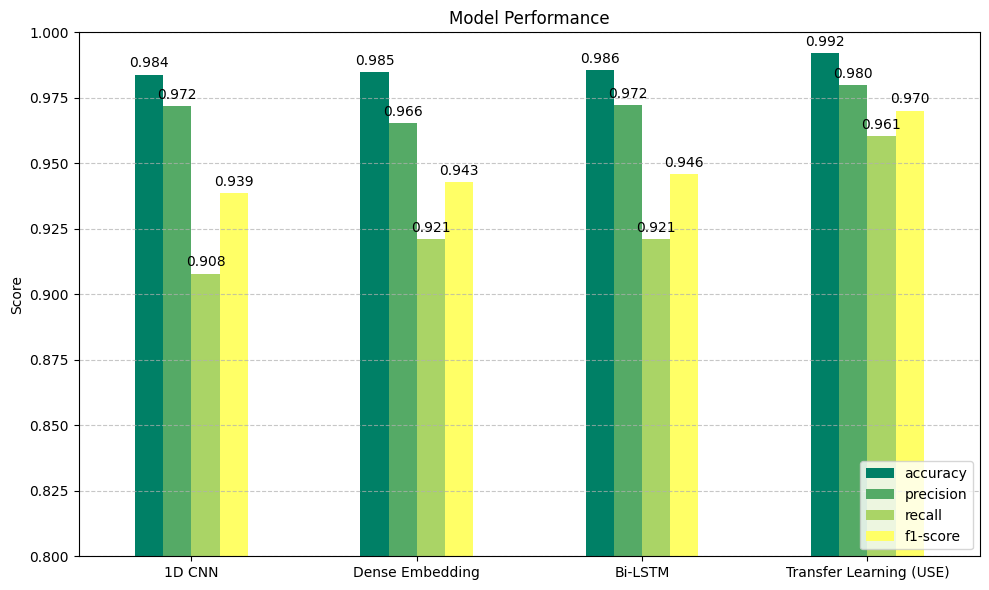

In [39]:
ax = results_df.plot(kind='bar', figsize=(10,6), cmap='summer')

plt.title('Model Performance')
plt.ylabel('Score')
plt.ylim(0.8,1.0)
plt.xticks(rotation=0)
plt.legend(loc=('lower right'))
plt.grid(axis='y', linestyle='--', alpha=0.7)

for container in ax.containers:
  ax.bar_label(
      container,
      fmt='%.3f',
      padding=3
  )

plt.tight_layout()
plt.show()

**1D CNN:**
- The model achieves an accuracy of 98.4%, with a precision of 97.2%, recall of 90.8%, and F1-score of 93.9%. Although the accuracy and precision are high, the relatively lower recall indicates that the model misses a larger proportion of positive instances compared with the other models.

**Dense Embedding:**
- The model achieves 98.5% accuracy, with 96.6% precision, 92.1% recall, and an F1-score of 94.3%. Compared with the 1D CNN, it has slightly higher accuracy and recall, resulting in a higher F1-score.

**Bi-LSTM:**
- The Bi-LSTM achieves 98.6% accuracy, 97.2% precision, 92.1% recall, and an F1-score of 94.6%. Its performance is relatively consistent across the metrics, with the highest F1-score among the first three models.

**Transfer Learning (USE):**
- The Transfer Learning model achieves 99.2% accuracy, 98.0% precision, 96.1% recall, and 97.0% F1-score. **It has the highest value for each of the four reported evaluation metrics among the models shown.**

# In Conclusion:

 The Transfer Learning (USE) model achieved the highest values across all four metrics (99.2% accuracy, 98.0% precision, 96.1% recall, and a 97.0% F1-score). Its higher recall indicates stronger performance in identifying positive instances compared with the other models.

 Overall, the test results of all models indicate that they generalize well to the test data, and the Transfer Learning (USE) model in particular proved to be the best performing model among the tested 4, in this evaluation setup.